## 1.Setup

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 50)

DATA_DIR = os.environ.get("ROSSMANN_DIR", "/kaggle/input")   # where the CSVs live
SAVE_OUTPUT = False                                          # write cleaned files at the end?
OUTPUT_DIR = "cleaned_data"

## 2. Load & first look

In [2]:
WANTED = {"train", "test", "store"}

paths = {}
for root, _, names in os.walk(DATA_DIR):
    for fname in names:
        stem, ext = os.path.splitext(fname)
        if ext == ".csv" and stem in WANTED:
            paths[stem] = os.path.join(root, fname)

not_found = WANTED - paths.keys()
assert not not_found, f"Missing files: {not_found}"

data_raw = {
    name: pd.read_csv(path, dtype={"StateHoliday": "string"})
    for name, path in paths.items()
}

def overview(name, df):
    nulls = df.isna().sum()
    print(f"{name.upper():<6} shape = {df.shape}")
    print("       missing:", nulls[nulls > 0].to_dict() or "none")
    display(df.head(3))

for name in ["train", "test", "store"]:
    overview(name, data_raw[name])

TRAIN  shape = (1017209, 9)
       missing: none


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1


TEST   shape = (41088, 8)
       missing: {'Open': 11}


,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday
0,1,1,4,2015-09-17,1.0,1,0,0
1,2,3,4,2015-09-17,1.0,1,0,0
2,3,7,4,2015-09-17,1.0,1,0,0


STORE  shape = (1115, 10)
       missing: {'CompetitionDistance': 3, 'CompetitionOpenSinceMonth': 354, 'CompetitionOpenSinceYear': 354, 'Promo2SinceWeek': 544, 'Promo2SinceYear': 544, 'PromoInterval': 544}


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"


### What the first look tells us
- **`train`** has no missing values, but `StateHoliday` mixes numbers and letters, and `Date` is still plain text.
- **`test`** has **11 missing `Open` values** — a problem, because `Open` decides whether a store sells anything at all.
- **`store`** has missing values in the competition fields (3 + 354 + 354) and in the Promo2 fields (544 each). We need to find out whether these are *errors* or *by design*.

In [3]:
# Untouched originals live in data_raw; we only ever modify the working copies.
train = data_raw["train"].copy(deep=True)
test  = data_raw["test"].copy(deep=True)
store = data_raw["store"].copy(deep=True)

print("Working copies ready →", train.shape, test.shape, store.shape)

Working copies ready → (1017209, 9) (41088, 8) (1115, 10)


## 3. Cleaning `train.csv`

### 3.1 Dates and table integrity
First, convert `Date` to a real datetime in **both** `train` and `test` (so every later check can use it), then verify the basics: no exact duplicates, no duplicated `Store`+`Date` pair, and `test` starts right after `train` ends.

In [4]:
for df in (train, test):
    df["Date"] = pd.to_datetime(df["Date"], errors="raise")   # raises if any date is invalid

def integrity_report(df, key):
    return pd.Series({
        "rows": len(df),
        "exact duplicate rows": df.duplicated().sum(),
        f"duplicate {key}": df.duplicated(subset=key).sum(),
        "first date": df["Date"].min().date(),
        "last date": df["Date"].max().date(),
    })

display(pd.DataFrame({
    "train": integrity_report(train, ["Store", "Date"]),
    "test":  integrity_report(test,  ["Store", "Date"]),
}))

assert train["Date"].max() < test["Date"].min(), "train and test periods overlap!"

,train,test
rows,1017209,41088
exact duplicate rows,0,0
"duplicate ['Store', 'Date']",0,0
first date,2013-01-01,2015-08-01
last date,2015-07-31,2015-09-17


**Result:** no duplicates, no invalid dates, and the periods are cleanly separated — `test` is a pure forecast of the 48 days after `train`.

### 3.2 `StateHoliday` — standardize the codes
Valid codes: `0` = none · `a` = public holiday · `b` = Easter · `c` = Christmas.
We trim whitespace and make sure nothing outside these four codes exists.

In [5]:
VALID_HOLIDAYS = ["0", "a", "b", "c"]

for df in (train, test):
    df["StateHoliday"] = df["StateHoliday"].str.strip()

display(pd.DataFrame({
    "train": train["StateHoliday"].value_counts(dropna=False),
    "test":  test["StateHoliday"].value_counts(dropna=False),
}).fillna(0).astype(int))

assert train["StateHoliday"].isin(VALID_HOLIDAYS).all()
assert test["StateHoliday"].isin(VALID_HOLIDAYS).all()

,train,test
StateHoliday,,
0,986159,40908
a,20260,180
b,6690,0
c,4100,0


Only the four expected codes exist. Note that `test` contains **only `0` and `a`** — no Easter or Christmas in the forecast window. We will keep all four categories anyway (section 6) so train and test stay compatible.

### 3.3 Business-rule checks (`Open` vs `Sales` vs `Customers`)
A store that is closed cannot have sales or customers, and a store with sales must have had customers. Let's test those rules.

In [6]:
is_open = train["Open"] == 1

rules = pd.Series({
    "Closed but Sales > 0":                    ((~is_open) & (train["Sales"] > 0)).sum(),
    "Closed but Customers > 0":                ((~is_open) & (train["Customers"] > 0)).sum(),
    "Open, Sales = 0":                         (is_open & (train["Sales"] == 0)).sum(),
    "Open, Sales = 0, Customers > 0":          (is_open & (train["Sales"] == 0) & (train["Customers"] > 0)).sum(),
    "Open, Customers = 0, Sales > 0":          (is_open & (train["Customers"] == 0) & (train["Sales"] > 0)).sum(),
    "Negative Sales or Customers":             ((train["Sales"] < 0) | (train["Customers"] < 0)).sum(),
}, name="rows")
display(rules.to_frame())

,rows
Closed but Sales > 0,0
Closed but Customers > 0,0
"Open, Sales = 0",54
"Open, Sales = 0, Customers > 0",2
"Open, Customers = 0, Sales > 0",0
Negative Sales or Customers,0


### 3.4 The 54 "open but zero sales" rows
Closed stores behave perfectly (0 violations). The only anomaly is **54 rows where the store is open but sold nothing**. Let's see whether it looks like a pattern or random noise.

In [7]:
open_zero = train[is_open & (train["Sales"] == 0)]

print(f"Rows: {len(open_zero)} | stores affected: {open_zero['Store'].nunique()} | dates affected: {open_zero['Date'].nunique()}")

display(open_zero["Customers"].value_counts().rename("rows").to_frame("rows").rename_axis("Customers"))

# The two rows that also report customers: look at ±3 days around them
suspicious = open_zero[open_zero["Customers"] > 0]
for _, row in suspicious.iterrows():
    window = train[
        (train["Store"] == row["Store"])
        & train["Date"].between(row["Date"] - pd.Timedelta(days=3), row["Date"] + pd.Timedelta(days=3))
    ].sort_values("Date")
    print(f"\nStore {row['Store']} around {row['Date'].date()}")
    display(window[["Date", "DayOfWeek", "Open", "Sales", "Customers", "Promo"]])

Rows: 54 | stores affected: 41 | dates affected: 49


,rows
Customers,
0,52
3,1
5,1



Store 1100 around 2014-04-29


,Date,DayOfWeek,Open,Sales,Customers,Promo
481994,2014-04-26,6,0,0,0,0
480879,2014-04-27,7,0,0,0,0
479764,2014-04-28,1,0,0,0,1
478649,2014-04-29,2,1,0,3,1
477534,2014-04-30,3,1,0,0,1
476419,2014-05-01,4,0,0,0,1
475304,2014-05-02,5,0,0,0,1



Store 948 around 2013-04-25


,Date,DayOfWeek,Open,Sales,Customers,Promo
893277,2013-04-22,1,0,0,0,1
892162,2013-04-23,2,0,0,0,1
891047,2013-04-24,3,0,0,0,1
889932,2013-04-25,4,1,0,5,1
888817,2013-04-26,5,1,8520,1880,1
887702,2013-04-27,6,1,5340,1241,0
886587,2013-04-28,7,1,7404,1630,0


### Decision: keep these rows (documented, not deleted)
- 52 of the 54 rows have **0 customers too**, so they look like closures that were not flagged as `Open = 0` (refurbishment, staff shortage, …).
- The other 2 sit inside stretches where the store was closed for days — most likely data-entry noise.
- They are only **0.005 %** of the data, so they cannot distort aggregates, and removing rows from a time series can break lag/rolling features later.

**For modeling:** consider excluding `Open == 1 & Sales == 0` when training. (The competition's RMSPE metric also ignores zero-sales days, so these rows carry no evaluation weight.)

## 4. Cleaning `test.csv`

### 4.1 Integrity checks
Duplicates and dates were already verified in 3.1. What is left is the `Id` column (it must be a clean 1…N sequence because it is the submission key) and the value domains of the flag columns.

In [8]:
assert test["Id"].is_unique
assert test["Id"].min() == 1 and test["Id"].max() == len(test), "Id is not a clean 1..N sequence"

print("Id column: unique and contiguous, 1 →", test["Id"].max())

display(pd.DataFrame({
    "Open":          test["Open"].value_counts(dropna=False),
    "Promo":         test["Promo"].value_counts(dropna=False),
    "SchoolHoliday": test["SchoolHoliday"].value_counts(dropna=False),
}).fillna(0).astype(int))

Id column: unique and contiguous, 1 → 41088


,Open,Promo,SchoolHoliday
0.0,5984,24824,22866
1.0,35093,16264,18222
NaN,11,0,0


### 4.2 Missing `Open` values
`Open` is the single most important column for forecasting (a closed store has sales = 0), so these 11 gaps matter. First question: **which store(s) do they belong to?**

In [9]:
missing_open = test[test["Open"].isna()]

print("Stores with missing Open:", missing_open["Store"].unique().tolist())
display(missing_open[["Id", "Store", "Date", "DayOfWeek", "Promo", "StateHoliday", "SchoolHoliday"]].sort_values("Date"))

Stores with missing Open: [622]


,Id,Store,Date,DayOfWeek,Promo,StateHoliday,SchoolHoliday
10751,10752,622,2015-09-05,6,0,0,0
9039,9040,622,2015-09-07,1,0,0,0
8183,8184,622,2015-09-08,2,0,0,0
7327,7328,622,2015-09-09,3,0,0,0
6471,6472,622,2015-09-10,4,0,0,0
5615,5616,622,2015-09-11,5,0,0,0
4759,4760,622,2015-09-12,6,0,0,0
3047,3048,622,2015-09-14,1,1,0,0
2191,2192,622,2015-09-15,2,1,0,0
1335,1336,622,2015-09-16,3,1,0,0


All 11 rows belong to **one single store (622)**, on consecutive days. This is not random noise, so a global fill (mode/median) would be careless. Let's look at how store 622 *actually behaved* in `train`.

In [10]:
hist_622 = train[train["Store"] == 622]

open_rate = hist_622.groupby("DayOfWeek")["Open"].mean()
display(open_rate.round(3).to_frame("historical open rate").T.rename_axis(columns="DayOfWeek"))

print("Missing rows fall on weekdays:", sorted(missing_open["DayOfWeek"].unique()))

DayOfWeek,1,2,3,4,5,6,7
historical open rate,0.955,0.993,0.978,0.941,0.956,1.0,0.0


Missing rows fall on weekdays: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


### Decision: impute from the store's own weekday pattern
Store 622 is open **94–100 % of the time Monday–Saturday and never on Sunday**. None of the 11 missing days is a Sunday, so the weekday rule gives `Open = 1` for all of them.

We apply the rule per weekday (open if the historical rate ≥ 50 %) rather than hard-coding `1`, so the logic stays correct and auditable.

In [11]:
mask = test["Open"].isna()
assert test.loc[mask, "Store"].eq(622).all()

before = mask.sum()
test.loc[mask, "Open"] = test.loc[mask, "DayOfWeek"].map(open_rate.ge(0.5).astype(int))

print(f"Imputed {before} rows | missing Open now: {test['Open'].isna().sum()}")
display(test["Open"].value_counts().rename("rows").to_frame())

Imputed 11 rows | missing Open now: 0


,rows
Open,
1.0,35104
0.0,5984


## 5. Cleaning `store.csv`

### 5.1 Keys and relationships
Every store in `train`/`test` must have a metadata row, and `Store` must be unique in this table.

In [12]:
store_ids = set(store["Store"])

pd.Series({
    "duplicate Store IDs": store["Store"].duplicated().sum(),
    "train stores without metadata": len(set(train["Store"]) - store_ids),
    "test stores without metadata":  len(set(test["Store"])  - store_ids),
    "stores that never appear in test": len(store_ids - set(test["Store"])),
}, name="count").to_frame()

,count
duplicate Store IDs,0
train stores without metadata,0
test stores without metadata,0
stores that never appear in test,259


Keys are consistent. (259 stores are not in the forecast window — that is expected and harmless.)

### 5.2 Understand the missingness *before* touching it
Two separate groups of missing values: **competition** and **Promo2**. We check whether they are random or structural.

In [13]:
print("Missing values per column:")
display(store.isna().sum()[lambda s: s > 0].to_frame("missing"))

comp_cols = ["CompetitionDistance", "CompetitionOpenSinceMonth", "CompetitionOpenSinceYear"]
print("Missingness pattern of the three competition columns (True = missing):")
display(store[comp_cols].isna().value_counts().rename("stores").to_frame())

Missing values per column:


,missing
CompetitionDistance,3
CompetitionOpenSinceMonth,354
CompetitionOpenSinceYear,354
Promo2SinceWeek,544
Promo2SinceYear,544
PromoInterval,544


Missingness pattern of the three competition columns (True = missing):


stores
CompetitionDistance CompetitionOpenSinceMonth CompetitionOpenSinceYear        
False               False                     False                        761
                    True                      True                         351
True                True                      True                           3

**Competition columns — three groups:**
- 761 stores: everything known.
- **351 stores:** distance known, but *when* the competitor opened is unknown.
- **3 stores:** nothing known (distance is missing too).

Month and year are always missing together, so they can be handled as one unit.

### 5.3 Promo2 — missing *by design*
Promo2 is a continuing promotion some stores join. If a store has `Promo2 = 0`, then "since which week/year" and "which months" simply do not exist. Let's prove that this is the rule and not a coincidence.

In [14]:
promo_cols = ["Promo2SinceWeek", "Promo2SinceYear", "PromoInterval"]

consistency = store.groupby("Promo2")[promo_cols].agg(lambda s: s.notna().sum())
consistency["stores"] = store.groupby("Promo2").size()
display(consistency)

assert store.loc[store["Promo2"] == 0, promo_cols].isna().all().all()
assert store.loc[store["Promo2"] == 1, promo_cols].notna().all().all()

,Promo2SinceWeek,Promo2SinceYear,PromoInterval,stores
Promo2,,,,
0,0,0,0,544
1,571,571,571,571


**Confirmed:** the 544 stores with `Promo2 = 0` are exactly the ones with missing Promo2 details, and all 571 stores with `Promo2 = 1` are complete. These missing values are **not errors**.

### Decision for Promo2
Replace the "not applicable" gaps with explicit values so models and group-bys never meet a `NaN`:
- `PromoInterval` → `"NoPromo2"`
- `Promo2SinceWeek`, `Promo2SinceYear` → `0` (the `Promo2` flag already tells us this 0 means "none", not "week 0")

In [15]:
no_promo2 = store["Promo2"] == 0

store.loc[no_promo2, "PromoInterval"]   = "NoPromo2"
store.loc[no_promo2, "Promo2SinceWeek"] = 0
store.loc[no_promo2, "Promo2SinceYear"] = 0

display(store["PromoInterval"].value_counts(dropna=False).to_frame("stores"))
print("Remaining Promo2 NaNs:", store[promo_cols].isna().sum().sum())

,stores
PromoInterval,
NoPromo2,544
"Jan,Apr,Jul,Oct",335
"Feb,May,Aug,Nov",130
"Mar,Jun,Sept,Dec",106


Remaining Promo2 NaNs: 0


### 5.4 `CompetitionDistance` — 3 missing values
Before filling, look at the distribution: if it is heavily skewed the **mean would be misleading** and the **median** is the safer choice. Distance also differs a lot between store types, so we check that too.

skewness = 2.93  |  mean = 5,405 m  |  median = 2,325 m


,count,median,mean,min,max
StoreType,,,,,
a,601,1790.0,5123.061564,20.0,75860.0
b,17,900.0,1060.588235,90.0,3640.0
c,148,1660.0,3522.567568,40.0,45740.0
d,346,5040.0,6913.063584,50.0,48330.0


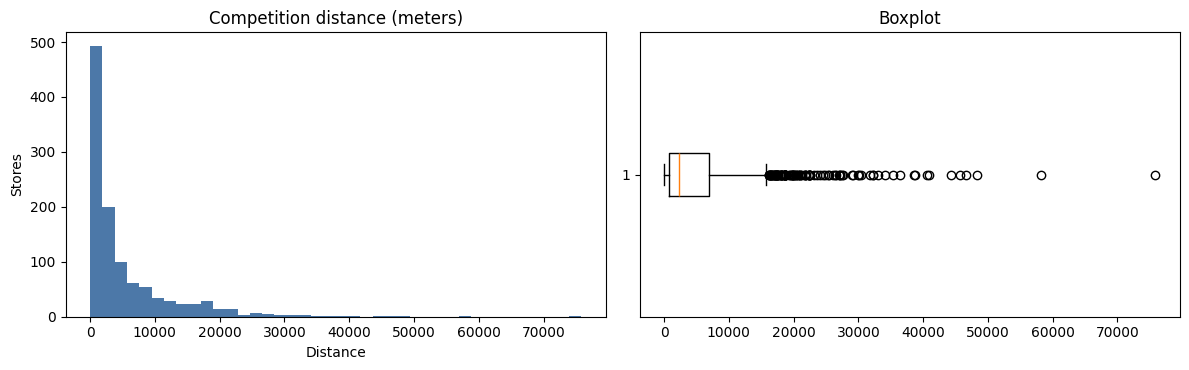

In [16]:
dist = store["CompetitionDistance"].dropna()
print(f"skewness = {dist.skew():.2f}  |  mean = {dist.mean():,.0f} m  |  median = {dist.median():,.0f} m")

display(store.groupby("StoreType", observed=True)["CompetitionDistance"].agg(["count", "median", "mean", "min", "max"]))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].hist(dist, bins=40, color="#4C78A8"); ax[0].set_title("Competition distance (meters)")
ax[0].set_xlabel("Distance"); ax[0].set_ylabel("Stores")
ax[1].boxplot(dist, vert=False); ax[1].set_title("Boxplot")
plt.tight_layout(); plt.show()

### Decision: fill with the **median of the store's own `StoreType`**
- Skewness ≈ 2.9 — a long right tail, so the mean (≈ 5,400 m) is far above the typical store (median ≈ 2,300 m).
- Medians differ strongly across types (≈ 900 m for type *b* up to ≈ 5,000 m for type *d*), so a type-specific median is a better guess than one global value.
- We also add a flag, `CompetitionDistance_WasMissing`, so a model can tell real values from filled ones.

In [17]:
store["CompetitionDistance_WasMissing"] = store["CompetitionDistance"].isna().astype("int8")

median_by_type = store.groupby("StoreType")["CompetitionDistance"].median()
gap = store["CompetitionDistance"].isna()
store.loc[gap, "CompetitionDistance"] = store.loc[gap, "StoreType"].map(median_by_type)

print("Missing distances after fill:", store["CompetitionDistance"].isna().sum())
display(store.loc[store["CompetitionDistance_WasMissing"] == 1, ["Store", "StoreType", "CompetitionDistance"]])

Missing distances after fill: 0


,Store,StoreType,CompetitionDistance
290,291,d,5040.0
621,622,a,1790.0
878,879,d,5040.0


### 5.5 Competition start date (354 stores)
We cannot invent a date for a competitor we know nothing about, and the true date is unrecoverable. So instead of guessing:
- add a flag **`CompetitionDateKnown`** (1 = we know it, 0 = we don't),
- fill month and year with `0` as an explicit "unknown" marker.

> **Heads-up for feature engineering:** `0` here is a *placeholder*, not a real year. When you later compute "months since competition opened", mask these rows using `CompetitionDateKnown` first, otherwise you will get nonsense values like "2,015 years of competition".

In [18]:
store["CompetitionDateKnown"] = (
    store["CompetitionOpenSinceMonth"].notna() & store["CompetitionOpenSinceYear"].notna()
).astype("int8")

store["CompetitionOpenSinceMonth"] = store["CompetitionOpenSinceMonth"].fillna(0)
store["CompetitionOpenSinceYear"]  = store["CompetitionOpenSinceYear"].fillna(0)

display(store["CompetitionDateKnown"].value_counts().rename({1: "known", 0: "unknown"}).to_frame("stores"))
print("Remaining NaNs in store:", store.isna().sum().sum())

,stores
CompetitionDateKnown,
known,761
unknown,354


Remaining NaNs in store: 0


## 6. Data-type optimization

Now that nothing is missing, we can safely shrink the types. This cuts memory use a lot (important for a 1M-row table) and makes the schema self-documenting:
- small integers for IDs and 0/1 flags,
- `category` for text columns with few distinct values,
- `StateHoliday` gets a **fixed category list** `[0, a, b, c]` in both train and test, so they always agree even though test has no `b`/`c`.

In [19]:
holiday_type = pd.CategoricalDtype(categories=VALID_HOLIDAYS)

# ── train ──
train = train.astype({
    "Store": "int16", "DayOfWeek": "int8", "Sales": "int32", "Customers": "int32",
    "Open": "int8", "Promo": "int8", "SchoolHoliday": "int8",
})
train["StateHoliday"] = train["StateHoliday"].astype(str).astype(holiday_type)

# ── test ──
test = test.astype({
    "Id": "int32", "Store": "int16", "DayOfWeek": "int8",
    "Open": "int8", "Promo": "int8", "SchoolHoliday": "int8",
})
test["StateHoliday"] = test["StateHoliday"].astype(str).astype(holiday_type)

# ── store ──
store = store.astype({
    "Store": "int16", "Promo2": "int8",
    "CompetitionDistance": "float32",
    "CompetitionOpenSinceMonth": "int8", "CompetitionOpenSinceYear": "int16",
    "Promo2SinceWeek": "int8", "Promo2SinceYear": "int16",
    "StoreType": "category", "Assortment": "category", "PromoInterval": "category",
})

mb = lambda df: df.memory_usage(deep=True).sum() / 1024**2
display(pd.DataFrame({
    "before (MB)": {k: mb(data_raw[k]) for k in ["train", "test", "store"]},
    "after (MB)":  {"train": mb(train), "test": mb(test), "store": mb(store)},
}).round(2))

display(pd.DataFrame({"train": train.dtypes.astype(str), "test": test.dtypes.astype(str)}).fillna("—"))
display(store.dtypes.astype(str).to_frame("store dtype"))

,before (MB),after (MB)
train,160.06,22.31
test,6.15,0.74
store,0.22,0.02


,train,test
Customers,int32,—
Date,datetime64[ns],datetime64[ns]
DayOfWeek,int8,int8
Id,—,int32
Open,int8,int8
Promo,int8,int8
Sales,int32,—
SchoolHoliday,int8,int8
StateHoliday,category,category
Store,int16,int16


,store dtype
Store,int16
StoreType,category
Assortment,category
CompetitionDistance,float32
CompetitionOpenSinceMonth,int8
CompetitionOpenSinceYear,int16
Promo2,int8
Promo2SinceWeek,int8
Promo2SinceYear,int16
PromoInterval,category


## 7. Outlier analysis

We **detect and understand** outliers here, then decide whether they are errors (fix/remove) or real behaviour (keep).

Method: the classic **IQR rule** — a value is flagged if it lies more than 1.5 × IQR beyond Q1/Q3.

> For `Sales` and `Customers` we measure on **open days only**. Including closed days (all zeros) would drag Q1 down and distort the bounds.

train (open days):


,Q1,Q3,lower,upper,outliers,outlier %,min,max
column,,,,,,,,
Sales,4859.0,8360.0,-392.5,13611.5,30769,3.64,0,41551
Customers,519.0,893.0,-42.0,1454.0,40853,4.84,0,7388


store:


,Q1,Q3,lower,upper,outliers,outlier %,min,max
column,,,,,,,,
CompetitionDistance,720.0,6875.0,-8512.5,16107.5,108,9.69,20.0,75860.0


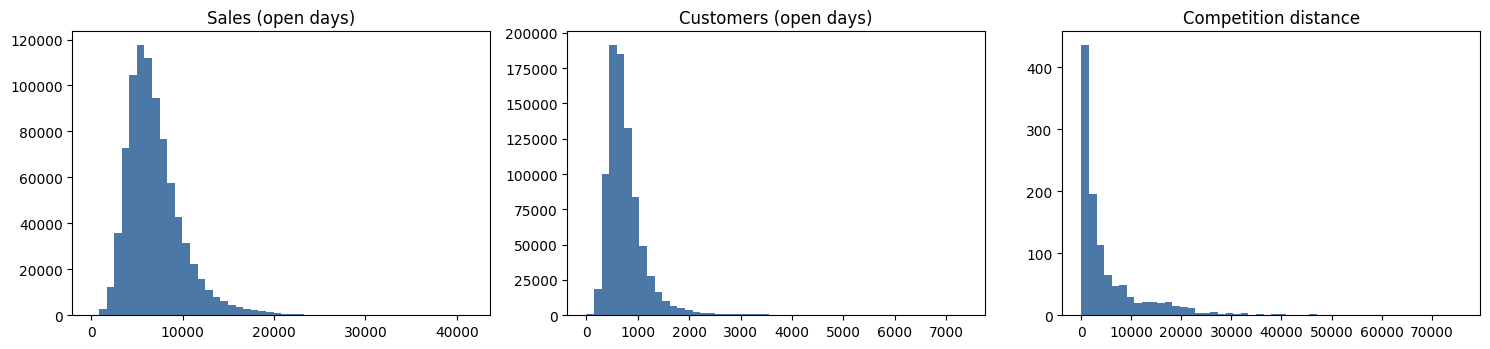

In [20]:
def iqr_report(df, columns):
    rows = []
    for col in columns:
        s = df[col].dropna()
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n = int(((s < lo) | (s > hi)).sum())
        rows.append({"column": col, "Q1": q1, "Q3": q3, "lower": lo, "upper": hi,
                     "outliers": n, "outlier %": round(n / len(s) * 100, 2),
                     "min": s.min(), "max": s.max()})
    return pd.DataFrame(rows).set_index("column")

open_days = train[train["Open"] == 1]

print("train (open days):")
display(iqr_report(open_days, ["Sales", "Customers"]))
print("store:")
display(iqr_report(store, ["CompetitionDistance"]))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, (data, col, title) in zip(ax, [
        (open_days, "Sales", "Sales (open days)"),
        (open_days, "Customers", "Customers (open days)"),
        (store, "CompetitionDistance", "Competition distance")]):
    a.hist(data[col], bins=50, color="#4C78A8"); a.set_title(title)
plt.tight_layout(); plt.show()

### Are the extreme sales values mistakes or genuinely big stores?
If outliers were data errors they would be scattered randomly. If they are real, they should **concentrate in a few stores**.

In [21]:
upper = iqr_report(open_days, ["Sales"]).loc["Sales", "upper"]
extreme = open_days[open_days["Sales"] > upper]

top = extreme["Store"].value_counts().head(5).rename("extreme-sales days").to_frame()
top["store's median sales"] = [open_days.loc[open_days["Store"] == s, "Sales"].median() for s in top.index]
display(top)

print(f"Overall median sales on open days: {open_days['Sales'].median():,.0f}")

,extreme-sales days,store's median sales
Store,,
262,940,19415.5
562,869,18029.5
1114,779,20412.5
251,769,18566.0
788,759,17494.0


Overall median sales on open days: 6,369


### Decision: **keep all outliers**
- Extreme days are **concentrated in a handful of stores** whose *normal* level is far above the chain average — they are big stores, not typos.
- Values stay inside a plausible range (max ≈ 41.5 k sales, ≈ 7.4 k customers) with no negatives or impossible numbers.
- `CompetitionDistance` is simply right-skewed: a few rural stores have competitors very far away. That is real information.
- Deleting or capping them would erase exactly the high-volume behaviour the forecast must capture.

If a model later turns out to be sensitive to the skew, prefer a **log transform** over removing rows.

## 8. Final validation

A last automated safety net. If any assumption of the cleaning phase is broken, the cell below fails loudly instead of letting bad data flow downstream.

In [22]:
tables = {"train": train, "test": test, "store": store}

# 1. No missing values anywhere
for name, df in tables.items():
    assert not df.isna().any().any(), f"{name} still has missing values: {df.isna().sum()[lambda s: s > 0].to_dict()}"

# 2. No duplicates / unique keys
for name, df in tables.items():
    assert not df.duplicated().any(), f"{name} has duplicate rows"
assert not train.duplicated(["Store", "Date"]).any()
assert not test.duplicated(["Store", "Date"]).any()
assert store["Store"].is_unique and test["Id"].is_unique

# 3. Valid domains
for df in (train, test):
    assert df["Open"].isin([0, 1]).all() and df["Promo"].isin([0, 1]).all() and df["SchoolHoliday"].isin([0, 1]).all()
    assert df["DayOfWeek"].between(1, 7).all()
assert store["Promo2"].isin([0, 1]).all()

# 4. Referential integrity
assert set(train["Store"]) <= set(store["Store"])
assert set(test["Store"])  <= set(store["Store"])

# 5. Business rules
assert train[["Sales", "Customers"]].ge(0).all().all()
assert train.loc[train["Open"] == 0, ["Sales", "Customers"]].eq(0).all().all()

# 6. Types & timeline
assert pd.api.types.is_datetime64_any_dtype(train["Date"]) and pd.api.types.is_datetime64_any_dtype(test["Date"])
assert train["Date"].max() < test["Date"].min()
assert list(train["StateHoliday"].cat.categories) == list(test["StateHoliday"].cat.categories) == VALID_HOLIDAYS

# 7. Raw data really untouched
assert data_raw["test"]["Open"].isna().any() and data_raw["store"].isna().any().any(), "raw data was modified!"

print("All validation checks passed")
for name, df in tables.items():
    print(f"   {name:<6} {df.shape}")

All validation checks passed
   train  (1017209, 9)
   test   (41088, 8)
   store  (1115, 12)


## 9. Summary of cleaning decisions

| # | Table | Issue found | Action | Why |
|---|---|---|---|---|
| 1 | train, test | `Date` stored as text | Converted to `datetime64` | Enables time logic; also confirmed train/test do not overlap |
| 2 | train | `StateHoliday` mixed numbers and letters | Read as string, trimmed, validated to `{0,a,b,c}`, later made a fixed `category` | Consistent codes across train and test |
| 3 | train | 54 open days with zero sales | **Kept**, documented | Tiny share; likely unrecorded closures; deleting breaks time series |
| 4 | test | 11 missing `Open` (all store 622) | Imputed from the store's weekday history | Store-specific evidence beats a global fill |
| 5 | store | `Promo2*` / `PromoInterval` missing for 544 stores | Filled with `0` / `"NoPromo2"` | Missing *by design* (no Promo2) |
| 6 | store | 3 missing `CompetitionDistance` | Median of the same `StoreType` + `_WasMissing` flag | Skewed data → median; types differ |
| 7 | store | 354 missing competition start date | `0` placeholder + `CompetitionDateKnown` flag | True date unrecoverable; do not invent one |
| 8 | all | Wide default dtypes | Downcast ints, `category`, `float32` | Lower memory, clearer schema |
| 9 | train, store | IQR outliers | **Kept** | Concentrated in genuinely large stores / far-away competitors |

### New columns created
`CompetitionDistance_WasMissing`, `CompetitionDateKnown` (both in `store`).

### Suggested next steps
1. Merge `store` into `train`/`test` on `Store`.
2. Build date features (year, month, week, day, days to/since holidays).
3. Turn competition and Promo2 info into durations — **masking the `0` placeholders first**.
4. Decide whether to exclude `Open == 1 & Sales == 0` rows from model training.

## 10. Saving the cleaned data
Disabled by default. Set `SAVE_OUTPUT = True` in the setup cell to write the files.

> CSV does not remember data types (`category`, `int8`, …). so we use Parquet.

In [23]:
SAVE_OUTPUT = True
if SAVE_OUTPUT:
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    
    train.to_parquet(os.path.join(OUTPUT_DIR, "train_cleaned.parquet"), index=False)
    test.to_parquet(os.path.join(OUTPUT_DIR, "test_cleaned.parquet"), index=False)
    store.to_parquet(os.path.join(OUTPUT_DIR, "store_cleaned.parquet"), index=False)
    
    print("Saved successufly Parquet!")

Saved successufly Parquet!
